In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [20]:

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target


features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
X = df[features]
y = df['target']

print("Features:", features)
print("Target: 0 = Malignant, 1 = Benign")
print("Total samples:", len(df))
print(y.value_counts())

Features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
Target: 0 = Malignant, 1 = Benign
Total samples: 569
target
1    357
0    212
Name: count, dtype: int64


In [21]:

df.head()

df[features].describe()
print("Missing values:", df[features].isnull().sum().sum())
print("Class counts:")
print(y.value_counts())


Missing values: 0
Class counts:
target
1    357
0    212
Name: count, dtype: int64


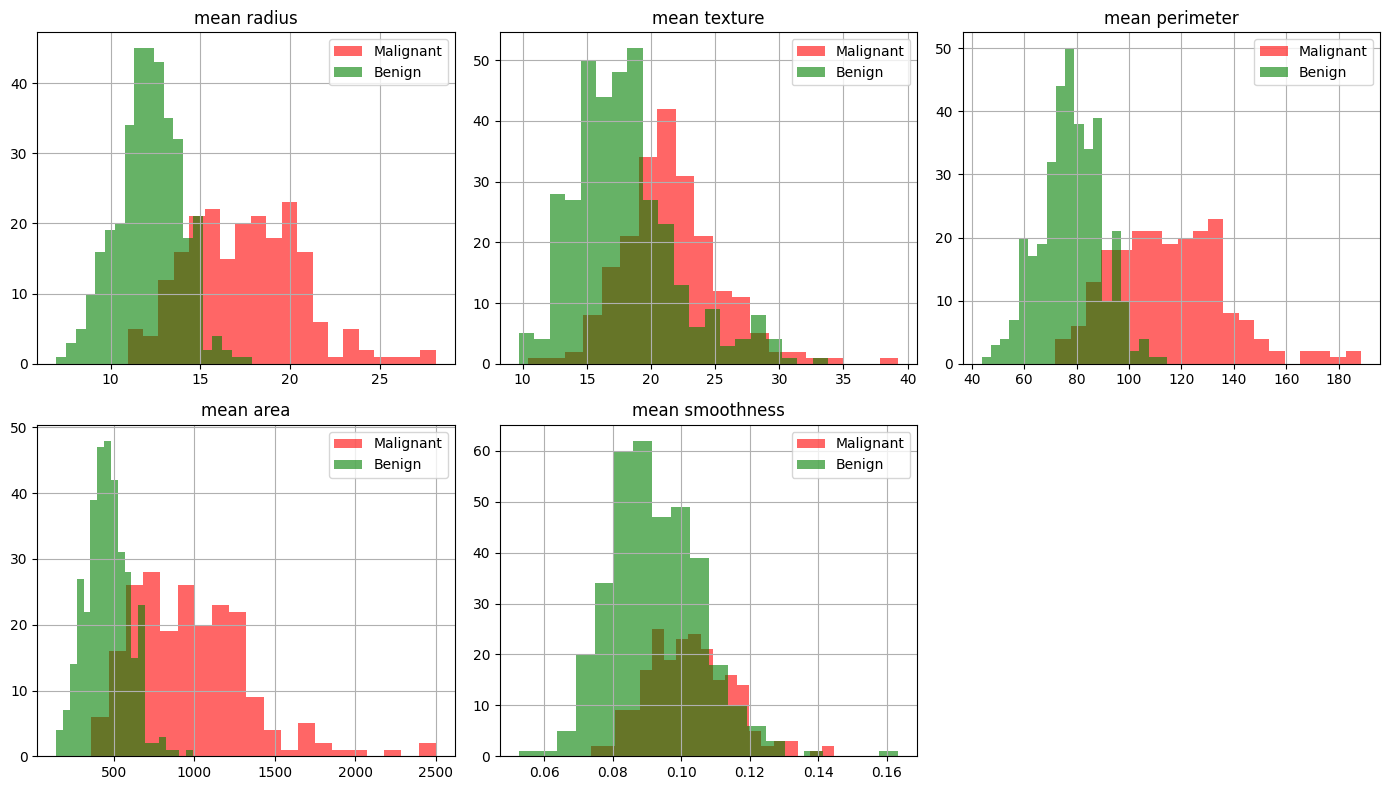

In [22]:

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for idx, feature in enumerate(features):
    ax = axes[idx // 3][idx % 3]
    df[df['target'] == 0][feature].hist(ax=ax, alpha=0.6, label='Malignant', color='red', bins=20)
    df[df['target'] == 1][feature].hist(ax=ax, alpha=0.6, label='Benign', color='green', bins=20)
    ax.set_title(feature)
    ax.legend()

axes[1][2].remove()
plt.tight_layout()
plt.show()



In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training size:", X_train.shape[0])
print("Testing size:", X_test.shape[0])


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Training size: 455
Testing size: 114


In [24]:
model = LogisticRegression()
model.fit(X_train, y_train)
print("model trained")

model trained


In [25]:
coef_df = pd.DataFrame({'feature': features, 'coefficient': model.coef_[0]})
print(coef_df)
print("intercept:", model.intercept_[0])


           feature  coefficient
0      mean radius    -1.133238
1     mean texture    -1.332419
2   mean perimeter    -1.707514
3        mean area    -1.393042
4  mean smoothness    -1.625640
intercept: 0.8303031564080862


In [26]:
y_pred = model.predict(X_test)
print("Predicted:", y_pred[:10])
print("Actual:   ", y_test.values[:10])

Predicted: [1 0 0 1 1 0 0 0 1 1]
Actual:    [1 0 0 1 1 0 0 0 1 1]


In [27]:
y_prob = model.predict_proba(X_test)

prob_df = pd.DataFrame({
    'P(Malignant)': y_prob[:, 0].round(3),
    'P(Benign)': y_prob[:, 1].round(3),
    'Predicted': y_pred,
    'Actual': y_test.values
})
prob_df.head(10)


,P(Malignant),P(Benign),Predicted,Actual
0,0.074,0.926,1,1
1,0.992,0.008,0,0
2,0.911,0.089,0,0
3,0.101,0.899,1,1
4,0.008,0.992,1,1
5,1.000,0.000,0,0
6,1.000,0.000,0,0
7,0.892,0.108,0,0
8,0.166,0.834,1,1
9,0.005,0.995,1,1


In [28]:
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)

print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1 Score :", round(f1, 4))



Accuracy : 0.9386
Precision: 0.9444
Recall   : 0.9577
F1 Score : 0.951


TN: 39 FP: 4
FN: 3 TP: 68


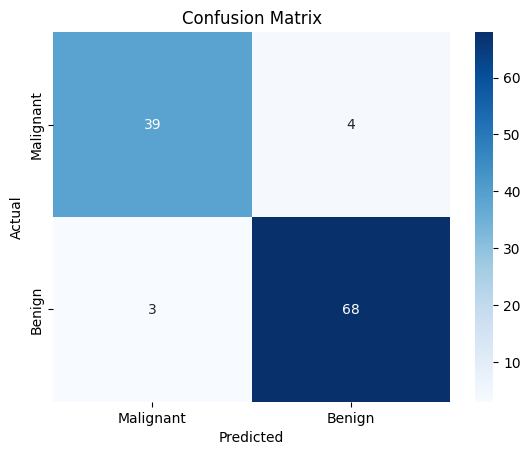

In [29]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("TN:", tn, "FP:", fp)
print("FN:", fn, "TP:", tp)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant', 'Benign'],
            yticklabels=['Malignant', 'Benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [30]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for t in thresholds:
    y_pred_t = (y_prob[:, 1] >= t).astype(int)
    print(f"Threshold {t} -> Accuracy: {accuracy_score(y_test, y_pred_t):.2f}  Precision: {precision_score(y_test, y_pred_t, zero_division=0):.2f}  Recall: {recall_score(y_test, y_pred_t, zero_division=0):.2f}")



Threshold 0.3 -> Accuracy: 0.95  Precision: 0.92  Recall: 1.00
Threshold 0.4 -> Accuracy: 0.96  Precision: 0.95  Recall: 1.00
Threshold 0.5 -> Accuracy: 0.94  Precision: 0.94  Recall: 0.96
Threshold 0.6 -> Accuracy: 0.94  Precision: 0.97  Recall: 0.93
Threshold 0.7 -> Accuracy: 0.93  Precision: 0.98  Recall: 0.90
